In [1]:
import torch
import torch.nn as nn
import math
import os
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from tqdm import tqdm
import matplotlib.pyplot as plt

In [2]:
# --- 1. ARQUITETURA DO TRANSFORMER (CORRIGIDA) ---

class SelfAttention(nn.Module):
    def __init__(self, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.softmax = nn.Softmax(dim=-1)

    def forward(self, Q, K, V, mask=None):
        d_k = Q.size(-1)
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, float('-inf'))
        atten = self.softmax(scores)
        return torch.matmul(self.dropout(atten), V), atten

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_k = d_model // num_heads
        self.num_heads = num_heads
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.fc = nn.Linear(d_model, d_model)
        self.attention = SelfAttention(dropout)
        self.dropout = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, q, k, v, mask=None):
        batch_size = q.size(0)
        Q = self.w_q(q).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        K = self.w_k(k).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        V = self.w_v(v).view(batch_size, -1, self.num_heads, self.d_k).transpose(1, 2)
        out, _ = self.attention(Q, K, V, mask)
        out = out.transpose(1, 2).contiguous().view(batch_size, -1, self.num_heads * self.d_k)
        return self.norm(self.dropout(self.fc(out)) + q)

class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x):
        out = self.fc2(self.dropout(torch.relu(self.fc1(x))))
        return self.norm(out + x)

class EncoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.feed_forward = FeedForward(d_model, d_ff, dropout)

    def forward(self, src, mask=None):
        out = self.self_attn(src, src, src, mask)
        return self.feed_forward(out)

class DecoderLayer(nn.Module):
    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, num_heads, dropout)
        self.feed_forward = FeedForward(d_model, d_ff, dropout)

    def forward(self, tgt, memory, tgt_mask=None, memory_mask=None):
        out = self.self_attn(tgt, tgt, tgt, tgt_mask)
        out = self.cross_attn(out, memory, memory, memory_mask)
        return self.feed_forward(out)

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float()*(-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

class Transformer(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d_model=512, num_head=8, num_layers=6, d_ff=2048, dropout=0.1):
        super().__init__()
        self.src_emb = nn.Embedding(src_vocab, d_model)
        self.tgt_emb = nn.Embedding(tgt_vocab, d_model)
        self.pos_enc = PositionalEncoding(d_model)
        self.encoder_layers = nn.ModuleList([EncoderLayer(d_model, num_head, d_ff, dropout) for _ in range(num_layers)])
        self.decoder_layers = nn.ModuleList([DecoderLayer(d_model, num_head, d_ff, dropout) for _ in range(num_layers)])
        self.fc_out = nn.Linear(d_model, tgt_vocab)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src, tgt, src_mask=None, tgt_mask=None, memory_mask=None):
        enc_out = self.dropout(self.pos_enc(self.src_emb(src) * math.sqrt(512)))
        for layer in self.encoder_layers:
            enc_out = layer(enc_out, src_mask)
        dec_out = self.dropout(self.pos_enc(self.tgt_emb(tgt) * math.sqrt(512)))
        for layer in self.decoder_layers:
            dec_out = layer(dec_out, enc_out, tgt_mask, memory_mask)
        return self.fc_out(dec_out)


In [3]:
# --- 2. FUNÇÕES DE TOKENIZAÇÃO E DADOS ---

def train_tokenizer(file_path, vocab_size=10000):
    """Treina um tokenizador BPE nos seus arquivos .en ou .pt"""
    tokenizer = Tokenizer(models.BPE(unk_token="[UNK]"))
    tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size, 
        special_tokens=["[PAD]", "[UNK]", "[SOS]", "[EOS]"]
    )
    tokenizer.train(files=[file_path], trainer=trainer)
    return tokenizer

def create_masks(src, tgt, pad_idx):
    src_mask = (src != pad_idx).unsqueeze(1).unsqueeze(2)
    tgt_seq_len = tgt.size(1)
    look_ahead_mask = torch.tril(torch.ones((tgt_seq_len, tgt_seq_len), device=src.device)).bool()
    tgt_pad_mask = (tgt != pad_idx).unsqueeze(1).unsqueeze(2)
    tgt_mask = look_ahead_mask & tgt_pad_mask
    return src_mask, tgt_mask


Treinando tokenizadores...






Codificando frases...

Iniciando treinamento com 100000 frases...


Época 1/50: 1563it [10:27,  2.49it/s, acc=82.30%, loss=2.6494]


Modelo e Tokenizadores salvos com sucesso!


Época 2/50: 1563it [10:26,  2.50it/s, acc=84.96%, loss=2.3835]


Modelo e Tokenizadores salvos com sucesso!


...

Modelo e Tokenizadores salvos com sucesso!


Época 49/50: 1563it [10:22,  2.51it/s, acc=96.02%, loss=1.6057]


Modelo e Tokenizadores salvos com sucesso!


Época 50/50: 1563it [10:22,  2.51it/s, acc=94.69%, loss=1.6294]


Modelo e Tokenizadores salvos com sucesso!

Treino concluído!


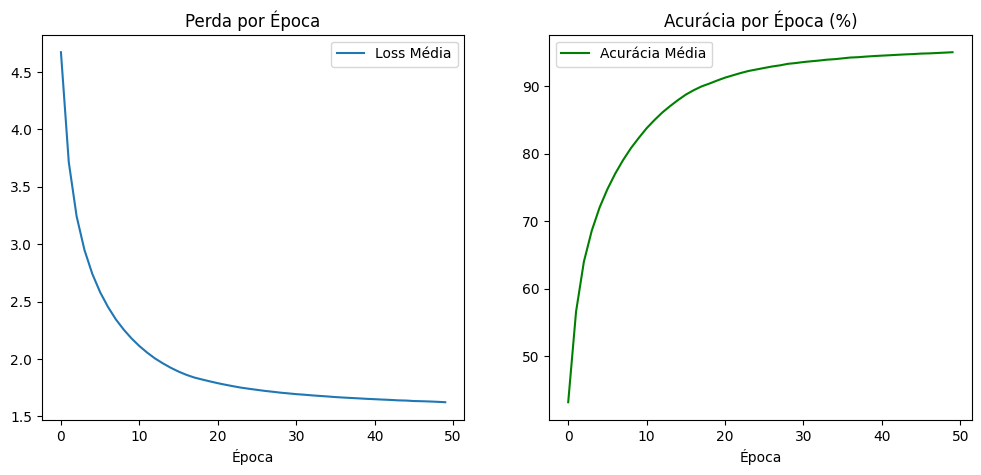

In [4]:
# --- 1. FUNÇÕES AUXILIARES (DEFINA ANTES DO TREINO) ---

def calculate_accuracy(output, target, pad_idx):
    """
    Calcula a porcentagem de palavras que o modelo acertou, 
    ignorando os tokens de preenchimento (PAD).
    """
    # Pega o ID da palavra com maior probabilidade (argmax)
    predictions = output.argmax(dim=-1)
    
    # Criamos uma máscara: True onde o target NÃO é PAD
    mask = (target != pad_idx)
    
    # Comparamos as predições com o real apenas onde não é PAD
    correct = (predictions == target) & mask
    
    # Soma os acertos e divide pelo total de palavras reais (não PAD)
    accuracy = correct.sum().item() / mask.sum().item()
    return accuracy

def train_tokenizer(file_path, vocab_size=15000):
    tokenizer = Tokenizer(models.BPE(unk_token="[UNK]"))
    tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size, 
        special_tokens=["[PAD]", "[UNK]", "[SOS]", "[EOS]"]
    )
    tokenizer.train(files=[file_path], trainer=trainer)
    return tokenizer

# --- 2. LOOP PRINCIPAL ---

if __name__ == "__main__":
    # Configurações iniciais
    EN_PATH = '/kaggle/input/datasets/traurigdrachen/pt-entransformer/Tatoeba.en-pt.en'
    PT_PATH = '/kaggle/input/datasets/traurigdrachen/pt-entransformer/Tatoeba.en-pt.pt'
    VOCAB_SIZE = 15000
    PAD_IDX = 0
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # 1. Treinar Tokenizadores
    print("Treinando tokenizadores...")
    tokenizer_pt = train_tokenizer(PT_PATH, VOCAB_SIZE)
    tokenizer_en = train_tokenizer(EN_PATH, VOCAB_SIZE)

    # 2. Instanciar Modelo, Loss e Optimizer
    # (Certifique-se de que a classe Transformer está definida acima deste bloco)
    model = Transformer(src_vocab=VOCAB_SIZE, tgt_vocab=VOCAB_SIZE).to(device)
    criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX, label_smoothing=0.1)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, betas=(0.9, 0.98))
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', patience=2, factor=0.5
    )

    # 3. Preparação dos Dados (Carregando as frases)
    num_frases = 100000 
    with open(PT_PATH, 'r', encoding='utf-8') as f_pt, open(EN_PATH, 'r', encoding='utf-8') as f_en:
        pt_lines = [f_pt.readline().strip() for _ in range(num_frases)]
        en_lines = [f_en.readline().strip() for _ in range(num_frases)]

    print("Codificando frases...")
    src_encoded = [tokenizer_pt.encode(line).ids for line in pt_lines]
    tgt_encoded = [tokenizer_en.encode(f"[SOS] {line} [EOS]").ids for line in en_lines]

    # --- 4. CONFIGURAÇÕES DE TREINO ---
    epochs = 50         # Com 100k frases, comece com poucas épocas, cada uma vai demorar
    batch_size = 64     # Processamos 128 frases por vez
    max_len = 60        # Tamanho máximo da frase
    history = {"epoch_loss": [], "epoch_acc": []}

    print(f"\nIniciando treinamento com {num_frases} frases...")
    
    for epoch in range(epochs):
        model.train()
        total_loss = 0
        total_acc = 0
        total_batches = len(src_encoded) // batch_size
        
        with tqdm(total=total_batches, desc=f"Época {epoch+1}/{epochs}") as pbar:
            for i in range(0, len(src_encoded), batch_size):
                # 1. Preparação do Batch
                batch_src_ids = src_encoded[i : i + batch_size]
                batch_tgt_ids = tgt_encoded[i : i + batch_size]
                actual_batch_size = len(batch_src_ids)
                
                src_batch = torch.zeros(actual_batch_size, max_len).long().to(device)
                tgt_batch = torch.zeros(actual_batch_size, max_len).long().to(device)

                for j, (s, t) in enumerate(zip(batch_src_ids, batch_tgt_ids)):
                    src_batch[j, :len(s[:max_len])] = torch.tensor(s[:max_len])
                    tgt_batch[j, :len(t[:max_len])] = torch.tensor(t[:max_len])

                tgt_input = tgt_batch[:, :-1]
                tgt_expected = tgt_batch[:, 1:]
                src_mask, tgt_mask = create_masks(src_batch, tgt_input, PAD_IDX)

                # 2. Forward e Loss
                optimizer.zero_grad()
                output = model(src_batch, tgt_input, src_mask, tgt_mask)
                
                loss = criterion(output.reshape(-1, VOCAB_SIZE), tgt_expected.reshape(-1))
                acc = calculate_accuracy(output.reshape(-1, VOCAB_SIZE), tgt_expected.reshape(-1), PAD_IDX)
                
                # 3. Backward + Gradient Clipping (Importante para estabilidade)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
                
                # Acumulando para a média da época
                total_loss += loss.item()
                total_acc += acc
                
                pbar.set_postfix(loss=f"{loss.item():.4f}", acc=f"{acc*100:.2f}%")
                pbar.update(1)

        # --- FIM DA ÉPOCA ---
        
        # 4. Cálculo das Médias da Época
        avg_loss = total_loss / total_batches
        avg_acc = total_acc / total_batches
        history["epoch_loss"].append(avg_loss)
        history["epoch_acc"].append(avg_acc)

        # 5. Atualização do Scheduler (Baseado na perda média da época)
        scheduler.step(avg_loss)

        # 6. Salvar o modelo (Checkpoint de segurança a cada época ou no final)
        torch.save({
            'model_state_dict': model.state_dict(),
            'tokenizer_pt': tokenizer_pt,
            'tokenizer_en': tokenizer_en,
            'vocab_size': VOCAB_SIZE,
            'pad_idx': PAD_IDX
        }, "tradutor_completo_v1.pth")
        
        print("Modelo e Tokenizadores salvos com sucesso!")

    print("\nTreino concluído!")

    # --- 5. VISUALIZAÇÃO AJUSTADA ---
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history["epoch_loss"], label="Loss Média")
    plt.xlabel("Época")
    plt.title("Perda por Época")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot([a*100 for a in history["epoch_acc"]], label="Acurácia Média", color="green")
    plt.xlabel("Época")
    plt.title("Acurácia por Época (%)")
    plt.legend()
    plt.show()

In [5]:
def translate(model, sentence, tokenizer_pt, tokenizer_en, device='cpu', max_len=50):
    model.eval()
    model.to(device)

    # 1. Preparar a entrada
    tokens_pt = tokenizer_pt.encode(sentence).ids
    src = torch.tensor([tokens_pt]).long().to(device)

    with torch.no_grad():
        # 2. Lógica Manual do Encoder (Copiada do seu forward)
        # Aplica Embedding + Positional Encoding + Dropout
        enc_out = model.dropout(model.pos_enc(model.src_emb(src) * math.sqrt(512)))
        # Itera sobre o ModuleList (A correção para o erro de NotImplementedError)
        for layer in model.encoder_layers:
            enc_out = layer(enc_out, None) # src_mask=None aqui
        memory = enc_out

    # 3. Preparar o Decoder
    sos_id = tokenizer_en.token_to_id("[SOS]")
    eos_id = tokenizer_en.token_to_id("[EOS]")
    tgt_tokens = [sos_id]

    for _ in range(max_len):
        tgt = torch.tensor([tgt_tokens]).long().to(device)
        
        # Gerar máscara de look-ahead
        size = tgt.size(1)
        tgt_mask = torch.triu(torch.ones(size, size), diagonal=1).bool().to(device) == 0

        # 4. Lógica Manual do Decoder (Copiada do seu forward)
        with torch.no_grad():
            dec_out = model.dropout(model.pos_enc(model.tgt_emb(tgt) * math.sqrt(512)))
            for layer in model.decoder_layers:
                # Passa a memória do encoder para a cross-attention
                dec_out = layer(dec_out, memory, tgt_mask, None)
            
            # Projeta para o vocabulário
            logits = model.fc_out(dec_out)
            
        # Pega a palavra mais provável
        next_token = logits[0, -1, :].argmax().item()
        tgt_tokens.append(next_token)

        if next_token == eos_id:
            break

    return tokenizer_en.decode(tgt_tokens)

In [6]:
# 1. Defina a frase que você quer traduzir
frase_para_traduzir = "Gosto de brincar com tanques de guerra."

# 2. Chame a função translate
# Certifique-se de que 'model', 'tokenizer_pt' e 'tokenizer_en' são os nomes das variáveis que você usou
resultado = translate(
    model=model, 
    sentence=frase_para_traduzir, 
    tokenizer_pt=tokenizer_pt, 
    tokenizer_en=tokenizer_en, 
    device='cuda' # ou 'cuda' se estiver usando GPU
)

# 3. Imprima o resultado na tela
print(f"Português: {frase_para_traduzir}")
print(f"Inglês (Tradução): {resultado}")

Português: Gosto de brincar com tanques de guerra.
Inglês (Tradução): We like to play with war . Is it a war war war thanks . They like to play with over a . on people .
